# Model-Based Policy Optimization (MBPO) for Flappy Bird

This notebook implements MBPO, a model-based reinforcement learning algorithm that trains a world model to generate imaginary rollouts, which are used alongside real environment data to train the policy efficiently.

## Setup and Imports

### Optimizations for Flappy Bird
This implementation includes several key optimizations:

1. **Latent-Based World Model** - Predicts only next latent representation and reward/terminal, eliminating expensive image decoding
2. **Ensemble World Models** - Uses 3 independent models to reduce model bias and improve rollout quality
3. **Uncertainty Estimation** - Reward predictions include uncertainty bounds (mean ± std)
4. **Pessimistic Rollouts** - Uses mean - coefficient × uncertainty for conservative reward estimates
5. **Adaptive Terminal Prediction** - Terminal threshold adapts based on prediction uncertainty
6. **Flappy Bird-Specific Parameters**:
   - Shorter rollout length (5 steps instead of 10+) 
   - More rollouts (150) to improve exploration
   - Higher world model training frequency (5 epochs)
   - Gradient clipping for stability

In [19]:
# Ensure cloudpickle is installed
%pip install cloudpickle
import os
os.environ['SDL_VIDEODRIVER'] = 'dummy'
os.environ['PYGAME_HIDE_SUPPORT_PROMPT'] = '1'
import warnings
warnings.filterwarnings('ignore')
import sys
sys.path.append('./flappy_bird_repo/game')
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import cv2
from torch.distributions import Categorical
import matplotlib.pyplot as plt

# Force reimport vec_env to get latest version
if 'vec_env' in sys.modules:
    del sys.modules['vec_env']
from vec_env import VecEnv

device = torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")
print(f"Using device: {device}")



[notice] A new release of pip is available: 23.0.1 -> 26.0.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Using device: mps


In [20]:
# ============= CHECKPOINT MANAGEMENT =============
import pickle
from pathlib import Path

def get_latest_checkpoint(checkpoint_dir='checkpoints/mbpo'):
    """Get the latest checkpoint file if it exists."""
    checkpoint_path = Path(checkpoint_dir)
    if not checkpoint_path.exists():
        return None
    checkpoint_files = sorted(checkpoint_path.glob('checkpoint_*.pkl'))
    return checkpoint_files[-1] if checkpoint_files else None

def save_checkpoint(checkpoint_dir, episode, agent, rewards, timestamp):
    """Save training checkpoint."""
    checkpoint_path = Path(checkpoint_dir)
    checkpoint_path.mkdir(parents=True, exist_ok=True)

    checkpoint_file = checkpoint_path / f'checkpoint_{episode:05d}_{timestamp}.pkl'
    checkpoint_data = {
        'episode': episode,
        'agent_state': {
            'policy': agent.policy.state_dict(),
            'latent_policy': agent.latent_policy.state_dict(),
            'world_models': [m.state_dict() for m in agent.world_models],
            'policy_optimizer': agent.policy_optimizer.state_dict(),
            'latent_policy_optimizer': agent.latent_policy_optimizer.state_dict(),
            'world_optimizers': [opt.state_dict() for opt in agent.world_optimizers],
        },
        'training_rewards': rewards,
        'hyperparams': {
            'gamma': agent.gamma,
            'eps_clip': agent.eps_clip,
            'batch_size': agent.batch_size,
        }
    }

    with open(checkpoint_file, 'wb') as f:
        pickle.dump(checkpoint_data, f)

    # Clean up old checkpoints (keep last 3)
    all_checkpoints = sorted(checkpoint_path.glob('checkpoint_*.pkl'))
    for old_checkpoint in all_checkpoints[:-3]:
        old_checkpoint.unlink()

    return checkpoint_file

def load_checkpoint(checkpoint_file, agent):
    """Load checkpoint and resume training."""
    with open(checkpoint_file, 'rb') as f:
        checkpoint_data = pickle.load(f)

    # Restore agent state
    agent.policy.load_state_dict(checkpoint_data['agent_state']['policy'])
    if 'latent_policy' in checkpoint_data['agent_state']:
        agent.latent_policy.load_state_dict(checkpoint_data['agent_state']['latent_policy'])
        agent.latent_policy_optimizer.load_state_dict(checkpoint_data['agent_state']['latent_policy_optimizer'])
    for model, state in zip(agent.world_models, checkpoint_data['agent_state']['world_models']):
        model.load_state_dict(state)

    agent.policy_optimizer.load_state_dict(checkpoint_data['agent_state']['policy_optimizer'])
    for opt, state in zip(agent.world_optimizers, checkpoint_data['agent_state']['world_optimizers']):
        opt.load_state_dict(state)

    return checkpoint_data['episode'], checkpoint_data['training_rewards']

# ============= RESUME SWITCH =============
RESUME_TRAINING = False  # Set to False to start fresh, True to resume from last checkpoint
print(f"Resume training: {RESUME_TRAINING}")


Resume training: False


## Define World Model

The world model predicts the next state and reward given the current state and action.

In [21]:
class WorldModel(nn.Module):
    """Latent-based world model for efficient Flappy Bird prediction."""
    def __init__(self, latent_dim=256):
        super(WorldModel, self).__init__()
        self.latent_dim = latent_dim
        
        # Encoder: compress state to latent
        self.encoder_conv1 = nn.Conv2d(4, 32, 8, stride=4, padding=2)
        self.encoder_conv2 = nn.Conv2d(32, 64, 4, stride=2, padding=1)
        self.encoder_conv3 = nn.Conv2d(64, 64, 3, stride=1, padding=1)
        self.encoder_fc = nn.Linear(64 * 10 * 10, latent_dim)
        
        # Dynamics model: predict next latent from latent + action
        self.dynamics_fc1 = nn.Linear(latent_dim + 2, 256)
        self.dynamics_fc2 = nn.Linear(256, 256)
        self.dynamics_latent = nn.Linear(256, latent_dim)
        
        # Reward prediction with uncertainty
        self.reward_fc = nn.Linear(256, 64)
        self.reward_mu = nn.Linear(64, 1)
        self.reward_std = nn.Linear(64, 1)
        
        # Terminal prediction (critical for Flappy Bird)
        self.terminal_fc = nn.Linear(256, 64)
        self.terminal_logit = nn.Linear(64, 1)

    def encode(self, state):
        x = F.relu(self.encoder_conv1(state))
        x = F.relu(self.encoder_conv2(x))
        x = F.relu(self.encoder_conv3(x))
        x = x.view(x.size(0), -1)
        latent = F.relu(self.encoder_fc(x))
        return latent

    def forward(self, latent, action_onehot):
        """Predict next latent, reward (mean & std), and terminal."""
        x = torch.cat([latent, action_onehot], dim=1)
        x = F.relu(self.dynamics_fc1(x))
        x = F.relu(self.dynamics_fc2(x))
        
        next_latent = F.relu(self.dynamics_latent(x))
        
        # Reward with uncertainty
        reward_x = F.relu(self.reward_fc(x))
        reward_mu = self.reward_mu(reward_x)
        reward_std = F.softplus(self.reward_std(reward_x)) + 0.01
        
        # Terminal prediction
        terminal_x = F.relu(self.terminal_fc(x))
        terminal_logit = self.terminal_logit(terminal_x)
        
        return next_latent, reward_mu, reward_std, terminal_logit


## Define Actor-Critic Policy

In [22]:
class ActorCritic(nn.Module):
    def __init__(self):
        super(ActorCritic, self).__init__()
        self.conv1 = nn.Conv2d(4, 32, 8, stride=4, padding=2)
        self.conv2 = nn.Conv2d(32, 64, 4, stride=2, padding=1)
        self.conv3 = nn.Conv2d(64, 64, 3, stride=1, padding=1)
        self.fc1 = nn.Linear(64 * 10 * 10, 512)
        self.actor = nn.Linear(512, 2)
        self.critic = nn.Linear(512, 1)
        self._init_weights()

    def _init_weights(self):
        for m in [self.conv1, self.conv2, self.conv3, self.fc1]:
            nn.init.orthogonal_(m.weight, gain=np.sqrt(2))
            nn.init.zeros_(m.bias)
        # Small actor init -> near-uniform initial policy (critical for exploration)
        nn.init.orthogonal_(self.actor.weight, gain=0.01)
        nn.init.zeros_(self.actor.bias)
        nn.init.orthogonal_(self.critic.weight, gain=1.0)
        nn.init.zeros_(self.critic.bias)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        return self.actor(x), self.critic(x)

class LatentActorCritic(nn.Module):
    """Latent-space actor-critic for imaginary rollout policy updates."""
    def __init__(self, latent_dim=256):
        super(LatentActorCritic, self).__init__()
        self.fc1 = nn.Linear(latent_dim, 256)
        self.fc2 = nn.Linear(256, 256)
        self.actor = nn.Linear(256, 2)
        self.critic = nn.Linear(256, 1)
        self._init_weights()

    def _init_weights(self):
        for m in [self.fc1, self.fc2]:
            nn.init.orthogonal_(m.weight, gain=np.sqrt(2))
            nn.init.zeros_(m.bias)
        nn.init.orthogonal_(self.actor.weight, gain=0.01)
        nn.init.zeros_(self.actor.bias)
        nn.init.orthogonal_(self.critic.weight, gain=1.0)
        nn.init.zeros_(self.critic.bias)

    def forward(self, latent):
        x = F.relu(self.fc1(latent))
        x = F.relu(self.fc2(x))
        return self.actor(x), self.critic(x)


## MBPO Agent Class

In [23]:
class MBPOAgent:
    """Optimized MBPO for Flappy Bird with ensemble world models, latent policy, and imaginary rollouts."""
    def __init__(self, lr=2.5e-4, gamma=0.99, eps_clip=0.2, k_epochs=4, lam=0.95, world_lr=1e-3, num_ensemble=3):
        self.device = device
        self.policy = ActorCritic().to(self.device)
        self.latent_policy = LatentActorCritic().to(self.device)

        # Ensemble of world models for reduced bias
        self.ensemble_size = num_ensemble
        self.world_models = nn.ModuleList([WorldModel().to(self.device) for _ in range(num_ensemble)])

        self.policy_optimizer = optim.Adam(self.policy.parameters(), lr=lr, eps=1e-5)
        self.latent_policy_optimizer = optim.Adam(self.latent_policy.parameters(), lr=lr, eps=1e-5)
        self.world_optimizers = [optim.Adam(m.parameters(), lr=world_lr) for m in self.world_models]

        self.gamma = gamma
        self.eps_clip = eps_clip
        self.k_epochs = k_epochs
        self.lam = lam
        self.batch_size = 256
        self.entropy_coef = 0.1  # constant - no annealing
        self.max_grad_norm = 0.5

        # Flappy Bird specific parameters
        self.rollout_length = 5   # Short rollouts (bird dies quickly)
        self.num_rollouts = 150   # Generate more trajectories
        self.pessimism_coef = 0.5
        self.uncertainty_penalty = 0.1

        self.MseLoss = nn.MSELoss()

    def preprocess(self, image):
        image = image.transpose(1, 0, 2)  # pygame surfarray (W,H,C) -> (H,W,C)
        image = cv2.cvtColor(cv2.resize(image, (80, 80)), cv2.COLOR_BGR2GRAY)
        return (image / 255.0).astype(np.float32)

    def select_action(self, state, use_policy=True):
        state = torch.from_numpy(state).float().unsqueeze(0).to(self.device)
        with torch.no_grad():
            action_logits, _ = self.policy(state)
            # CRITICAL: .squeeze(0) ensures logprob is a scalar [], not shape [1].
            # Without this, stacked logprobs become [N,1] and the ratio
            # exp(new[batch] - old[batch,1]) broadcasts to a [batch,batch] MATRIX,
            # completely corrupting the PPO surrogate loss.
            action_probs = F.softmax(action_logits, dim=-1).squeeze(0)
            if use_policy:
                dist = Categorical(action_probs)
                action = dist.sample()
                logprob = dist.log_prob(action)
            else:
                action = torch.argmax(action_probs, dim=-1)
                logprob = torch.log(action_probs[action] + 1e-8)
        return action.item(), logprob

    def select_latent_action(self, latent):
        """Select action using the latent-space policy."""
        with torch.no_grad():
            action_logits, _ = self.latent_policy(latent)
            action_probs = F.softmax(action_logits, dim=-1).squeeze(0)
            dist = Categorical(action_probs)
            action = dist.sample()
            logprob = dist.log_prob(action)
        return action.item(), logprob

    def train_world_model(self, memory, epochs=5):
        """Train ensemble of world models using held-out targets to avoid circular prediction."""
        states = torch.stack(memory.states).to(self.device).detach()
        actions = torch.stack(memory.actions).to(self.device).detach()
        next_states = torch.stack(memory.next_states).to(self.device).detach()
        rewards = torch.tensor(memory.rewards, dtype=torch.float32, device=self.device)
        terminals = torch.tensor(memory.is_terminals, dtype=torch.float32, device=self.device)

        # Compute all target latents once; use held-out members per model
        # to break circular prediction (model i targets mean of models j!=i)
        with torch.no_grad():
            all_target_latents = torch.stack(
                [model.encode(next_states) for model in self.world_models], dim=1
            )  # [N, ensemble_size, 256]

        world_loss_total = 0.0
        for epoch in range(epochs):
            action_onehot = F.one_hot(actions.long(), num_classes=2).float()

            for model_idx, model in enumerate(self.world_models):
                # Use mean of other models as target to break circular prediction
                other_idx = [j for j in range(self.ensemble_size) if j != model_idx]
                target_latent = all_target_latents[:, other_idx].mean(dim=1).detach()

                latents = model.encode(states)
                next_latent, reward_mu, reward_std, terminal_logit = model(latents, action_onehot)

                latent_loss = self.MseLoss(next_latent, target_latent)
                reward_loss = self.MseLoss(reward_mu.squeeze(-1), rewards) + 0.01 * reward_std.mean()
                terminal_loss = F.binary_cross_entropy_with_logits(terminal_logit.squeeze(-1), terminals)
                loss = latent_loss + reward_loss + 0.5 * terminal_loss

                self.world_optimizers[model_idx].zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                self.world_optimizers[model_idx].step()
                world_loss_total += loss.item()

        return world_loss_total / (self.ensemble_size * epochs)

    def generate_imaginary_rollouts(self, initial_states):
        """Generate rollouts in latent space using the latent-space policy."""
        imaginary_latents, imaginary_actions, imaginary_logprobs, imaginary_rewards, imaginary_terminals = [], [], [], [], []

        for _ in range(self.num_rollouts):
            state_idx = np.random.randint(0, len(initial_states))

            with torch.no_grad():
                latent = self.world_models[0].encode(initial_states[state_idx:state_idx+1])

            for step in range(self.rollout_length):
                # Use latent policy: action selection is now compatible with latent space
                action, latent_logprob = self.select_latent_action(latent)
                action_onehot = F.one_hot(torch.tensor([action], device=self.device), num_classes=2).float()

                with torch.no_grad():
                    predictions = []
                    for model in self.world_models:
                        next_lat, reward_mu, reward_std, terminal_logit = model(latent, action_onehot)
                        predictions.append((next_lat, reward_mu, reward_std, terminal_logit))

                    next_latent = torch.mean(torch.stack([p[0] for p in predictions]), dim=0)
                    reward_mu_ens = torch.mean(torch.stack([p[1] for p in predictions]), dim=0)
                    reward_std_ens = torch.mean(torch.stack([p[2] for p in predictions]), dim=0)
                    terminal_logit_ens = torch.mean(torch.stack([p[3] for p in predictions]), dim=0)

                    pessimistic_reward = reward_mu_ens - self.pessimism_coef * reward_std_ens

                    terminal_prob = torch.sigmoid(terminal_logit_ens)
                    terminal_uncertainty = reward_std_ens.abs().squeeze()
                    terminal_threshold = 0.4 + self.uncertainty_penalty * terminal_uncertainty.item()
                    terminal = (terminal_prob.squeeze() > terminal_threshold).item()

                imaginary_latents.append(latent.clone().squeeze(0))   # [256]
                imaginary_actions.append(torch.tensor(action, device=self.device))
                imaginary_logprobs.append(latent_logprob)
                imaginary_rewards.append(pessimistic_reward.item())
                imaginary_terminals.append(terminal)

                latent = next_latent
                if terminal:
                    break

        return imaginary_latents, imaginary_actions, imaginary_logprobs, imaginary_rewards, imaginary_terminals

    def update_policy(self, real_memory, imaginary_data, num_envs=1):
        """Update pixel policy on real data and latent policy on imaginary rollouts."""
        # ── Real data: PPO update on pixel-space policy ──
        all_logprobs = torch.stack(real_memory.logprobs).to(self.device).detach()
        all_states = torch.stack(real_memory.states).to(self.device).detach()
        all_actions = torch.stack(real_memory.actions).to(self.device).detach()
        all_rewards = torch.tensor(real_memory.rewards, dtype=torch.float32, device=self.device)
        all_terminals = torch.tensor(real_memory.is_terminals, dtype=torch.float32, device=self.device)

        with torch.no_grad():
            _, state_values = self.policy(all_states)
            state_values = state_values.squeeze(-1)

        # Compute GAE per-environment (buffer interleaved: e0t0, e1t0, ..., eNt0, e0t1, ...)
        N = len(all_rewards)
        advantages = torch.zeros(N, device=self.device)

        if num_envs > 1:
            T = N // num_envs
            for e in range(num_envs):
                idx = list(range(e, T * num_envs, num_envs))
                env_rew = all_rewards[idx]
                env_term = all_terminals[idx]
                env_val = state_values[idx]
                vals = torch.cat([env_val, torch.zeros(1, device=self.device)])
                gae = 0.0
                for t in reversed(range(T)):
                    delta = env_rew[t] + self.gamma * vals[t + 1] * (1 - env_term[t]) - vals[t]
                    gae = delta + self.gamma * self.lam * (1 - env_term[t]) * gae
                    advantages[idx[t]] = gae
        else:
            values = torch.cat((state_values, torch.zeros(1, device=self.device)))
            gae = 0.0
            for t in reversed(range(N)):
                delta = all_rewards[t] + self.gamma * values[t + 1] * (1 - all_terminals[t]) - values[t]
                gae = delta + self.gamma * self.lam * (1 - all_terminals[t]) * gae
                advantages[t] = gae

        returns = advantages + state_values
        advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-5)

        total_loss = 0.0
        dataset_size = len(all_rewards)
        for _ in range(self.k_epochs):
            perm = torch.randperm(dataset_size, device=self.device)
            for start_idx in range(0, dataset_size, self.batch_size):
                batch_idx = perm[start_idx:start_idx + self.batch_size]

                action_logits, state_values_batch = self.policy(all_states[batch_idx])
                action_probs = F.softmax(action_logits, dim=-1)
                dist = Categorical(action_probs)
                logprobs = dist.log_prob(all_actions[batch_idx])
                dist_entropy = dist.entropy().mean()

                ratios = torch.exp(logprobs - all_logprobs[batch_idx])
                state_values_batch = state_values_batch.squeeze(-1)

                surr1 = ratios * advantages[batch_idx]
                surr2 = torch.clamp(ratios, 1 - self.eps_clip, 1 + self.eps_clip) * advantages[batch_idx]
                loss = -torch.min(surr1, surr2).mean() + 0.5 * self.MseLoss(state_values_batch, returns[batch_idx]) - self.entropy_coef * dist_entropy

                self.policy_optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(self.policy.parameters(), self.max_grad_norm)
                self.policy_optimizer.step()
                total_loss += loss.item()

        # ── Imaginary data: PPO update on latent-space policy ──
        imag_latents, imag_actions, imag_logprobs, imag_rewards, imag_terminals = imaginary_data
        if len(imag_latents) > 0:
            imag_states_t  = torch.stack(imag_latents).to(self.device).detach()    # [M, 256]
            imag_actions_t = torch.stack(imag_actions).to(self.device).detach()    # [M]
            imag_logprobs_t = torch.stack(imag_logprobs).to(self.device).detach() # [M]
            imag_rewards_t  = torch.tensor(imag_rewards,   dtype=torch.float32, device=self.device)
            imag_terminals_t = torch.tensor(imag_terminals, dtype=torch.float32, device=self.device)

            with torch.no_grad():
                _, imag_values = self.latent_policy(imag_states_t)
                imag_values = imag_values.squeeze(-1)

            M = len(imag_rewards)
            imag_adv = torch.zeros(M, device=self.device)
            vals = torch.cat([imag_values, torch.zeros(1, device=self.device)])
            gae = 0.0
            for t in reversed(range(M)):
                delta = imag_rewards_t[t] + self.gamma * vals[t + 1] * (1 - imag_terminals_t[t]) - vals[t]
                gae = delta + self.gamma * self.lam * (1 - imag_terminals_t[t]) * gae
                imag_adv[t] = gae

            imag_returns = imag_adv + imag_values
            imag_adv = (imag_adv - imag_adv.mean()) / (imag_adv.std() + 1e-5)

            for _ in range(self.k_epochs):
                perm = torch.randperm(M, device=self.device)
                for start_idx in range(0, M, self.batch_size):
                    batch_idx = perm[start_idx:start_idx + self.batch_size]

                    action_logits, lat_values_batch = self.latent_policy(imag_states_t[batch_idx])
                    action_probs = F.softmax(action_logits, dim=-1)
                    dist = Categorical(action_probs)
                    logprobs = dist.log_prob(imag_actions_t[batch_idx])
                    dist_entropy = dist.entropy().mean()

                    ratios = torch.exp(logprobs - imag_logprobs_t[batch_idx])
                    lat_values_batch = lat_values_batch.squeeze(-1)

                    surr1 = ratios * imag_adv[batch_idx]
                    surr2 = torch.clamp(ratios, 1 - self.eps_clip, 1 + self.eps_clip) * imag_adv[batch_idx]
                    imag_loss = (-torch.min(surr1, surr2).mean()
                                 + 0.5 * self.MseLoss(lat_values_batch, imag_returns[batch_idx])
                                 - self.entropy_coef * dist_entropy)

                    self.latent_policy_optimizer.zero_grad()
                    imag_loss.backward()
                    torch.nn.utils.clip_grad_norm_(self.latent_policy.parameters(), self.max_grad_norm)
                    self.latent_policy_optimizer.step()

        return total_loss / (self.k_epochs * max(1, dataset_size // self.batch_size))


## Memory Classes

In [24]:
class Memory:
    def __init__(self):
        self.actions = []
        self.states = []
        self.next_states = []
        self.logprobs = []
        self.rewards = []
        self.is_terminals = []

    def clear_memory(self):
        del self.actions[:]
        del self.states[:]
        del self.next_states[:]
        del self.logprobs[:]
        del self.rewards[:]
        del self.is_terminals[:]

## Training Function

In [25]:

# Initialize MBPO Agent
print("Initializing MBPO Agent...")
agent = MBPOAgent(
    lr=2.5e-4,
    gamma=0.99,
    eps_clip=0.2,
    k_epochs=4,
    lam=0.95,
    world_lr=1e-3,
    num_ensemble=3
)
print(f"✓ Agent initialized on device: {agent.device}")
print(f"  World Models: {len(agent.world_models)} ensemble models")


Initializing MBPO Agent...
✓ Agent initialized on device: mps
  World Models: 3 ensemble models


In [26]:
# MBPO training loop (parallel envs)
import time as time_module
from collections import deque
from datetime import datetime

def train_mbpo(agent, num_episodes=200, update_timestep=2048, world_model_freq=5,
               resume_from_checkpoint=False, checkpoint_dir='checkpoints/mbpo',
               checkpoint_interval=1000, num_envs=6):
    from torch.utils.tensorboard import SummaryWriter
    run_name = f"mbpo_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
    writer = SummaryWriter(log_dir=f'runs/{run_name}')

    def make_env():
        import os
        import wrapped_flappy_bird as game
        return game.GameState()

    envs = VecEnv([make_env for _ in range(num_envs)])
    memory = Memory()

    all_rewards = []
    episode_reward = [0.0] * num_envs
    max_game_score = float('-inf')
    total_episodes = 0
    timestep = 0
    flap_count = 0
    total_actions = 0
    start_time = time_module.time()

    if resume_from_checkpoint:
        latest = get_latest_checkpoint(checkpoint_dir)
        if latest:
            start_ep, saved_rewards = load_checkpoint(latest, agent)
            all_rewards = saved_rewards
            total_episodes = start_ep
            print(f"Resumed from episode {start_ep}")

    obs_list = envs.reset()
    state_frames = [deque(maxlen=4) for _ in range(num_envs)]
    for i in range(num_envs):
        frame = agent.preprocess(obs_list[i])
        for _ in range(4):
            state_frames[i].append(frame)

    while total_episodes < num_episodes:
        states = [np.stack(list(state_frames[i]), axis=0) for i in range(num_envs)]

        actions = []
        logprobs = []
        for i in range(num_envs):
            action, logprob = agent.select_action(states[i])
            actions.append(action)
            logprobs.append(logprob)
            flap_count += (action == 1)
            total_actions += 1

        action_vecs = [[0, 1] if a == 1 else [1, 0] for a in actions]

        # Frame skipping: repeat each action for 4 raw frames (same as PPO).
        # Increases effective time per decision; makes pipe-passing reward much
        # stronger relative to the per-frame survival bonus.
        frame_skip = 4
        accumulated_rewards = [0.0] * num_envs
        env_done = [False] * num_envs
        skip_actions = list(action_vecs)
        for _ in range(frame_skip):
            obs_list, rewards_skip, dones_skip = envs.step(skip_actions)
            for i in range(num_envs):
                if not env_done[i]:
                    accumulated_rewards[i] += rewards_skip[i]
                    if dones_skip[i]:
                        env_done[i] = True
            skip_actions = [skip_actions[i] if not env_done[i] else [1, 0] for i in range(num_envs)]
        rewards_step = accumulated_rewards
        dones = env_done

        for i in range(num_envs):
            frame = agent.preprocess(obs_list[i])
            next_frames = list(state_frames[i])
            next_frames.append(frame)
            next_state = np.stack(next_frames[-4:], axis=0)

            memory.states.append(torch.from_numpy(states[i]).float())
            memory.next_states.append(torch.from_numpy(next_state).float())
            memory.actions.append(torch.tensor(actions[i]))
            memory.logprobs.append(logprobs[i])

            # Reward shaping: collapse survival noise so the agent can only improve
            # by passing pipes. Raw (after frame-skip=4): survival~0.4, pipe~1.3, death~-0.7
            # Shaped: survival=0.01, pipe=1.0, death=-1.0
            if rewards_step[i] > 0.5:
                shaped_reward = 1.0
            elif rewards_step[i] < -0.5:
                shaped_reward = -1.0
            else:
                shaped_reward = 0.01
            memory.rewards.append(shaped_reward)
            memory.is_terminals.append(dones[i])

            state_frames[i].append(frame)
            episode_reward[i] += rewards_step[i]  # raw reward for logging

            if dones[i]:
                total_episodes += 1
                all_rewards.append(episode_reward[i])
                if episode_reward[i] > max_game_score:
                    max_game_score = episode_reward[i]
                episode_reward[i] = 0.0

                writer.add_scalar('Episode Reward', all_rewards[-1], total_episodes)

                if total_episodes % 100 == 0:
                    avg = np.mean(all_rewards[-100:]) if len(all_rewards) >= 100 else np.mean(all_rewards)
                    flap_rate = flap_count / max(1, total_actions)
                    print(f"Episode: {total_episodes}, AvgReward100: {avg:.2f}, MaxGameScore: {max_game_score:.2f}, FlapRate: {flap_rate:.2f}")

                if total_episodes % checkpoint_interval == 0:
                    timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
                    save_checkpoint(checkpoint_dir, total_episodes, agent, all_rewards, timestamp)
                    print(f"  Checkpoint saved at episode {total_episodes}")

                frame = agent.preprocess(obs_list[i])
                state_frames[i] = deque(maxlen=4)
                for _ in range(4):
                    state_frames[i].append(frame)

                if total_episodes >= num_episodes:
                    break

        timestep += num_envs

        if len(memory.states) >= update_timestep:
            # Train world model from the first update onwards
            world_loss = agent.train_world_model(memory, epochs=world_model_freq)
            writer.add_scalar('World Model Loss', world_loss, timestep)
            # Start using imaginary rollouts after 5 real updates so the world model
            # has had enough data before generating synthetic experience
            if timestep >= update_timestep * 5:
                initial_states = torch.stack(memory.states).to(agent.device)
                imaginary_data = agent.generate_imaginary_rollouts(initial_states)
            else:
                imaginary_data = ([], [], [], [], [])
            policy_loss = agent.update_policy(memory, imaginary_data, num_envs=num_envs)
            writer.add_scalar('Policy Loss', policy_loss, timestep)
            writer.add_scalar('Real Transitions', len(memory.states), timestep)
            memory.clear_memory()

    envs.close()
    writer.close()
    training_time = time_module.time() - start_time
    return agent, all_rewards, training_time


## Train MBPO Agent

In [27]:
print("Training the MBPO agent...")
print(f"Resume training: {RESUME_TRAINING}\n")
agent, rewards, training_time = train_mbpo(
    agent,
    num_episodes=50000,
    update_timestep=2048,
    world_model_freq=5,
    resume_from_checkpoint=RESUME_TRAINING,
    checkpoint_dir='checkpoints/mbpo',
    checkpoint_interval=1000,
    num_envs=6
)
print(f"\nTraining completed in {training_time:.1f}s")


Training the MBPO agent...
Resume training: False

Episode: 100, AvgReward100: 3.69, MaxGameScore: 6.10, FlapRate: 0.50
Episode: 200, AvgReward100: 3.62, MaxGameScore: 6.20, FlapRate: 0.52
Episode: 300, AvgReward100: 3.64, MaxGameScore: 6.20, FlapRate: 0.51
Episode: 400, AvgReward100: 3.67, MaxGameScore: 6.20, FlapRate: 0.49
Episode: 500, AvgReward100: 3.56, MaxGameScore: 6.20, FlapRate: 0.48
Episode: 600, AvgReward100: 3.62, MaxGameScore: 6.30, FlapRate: 0.47
Episode: 700, AvgReward100: 3.68, MaxGameScore: 6.30, FlapRate: 0.47
Episode: 800, AvgReward100: 3.65, MaxGameScore: 6.30, FlapRate: 0.48
Episode: 900, AvgReward100: 3.71, MaxGameScore: 6.30, FlapRate: 0.48
Episode: 1000, AvgReward100: 3.74, MaxGameScore: 6.30, FlapRate: 0.49
  Checkpoint saved at episode 1000
Episode: 1100, AvgReward100: 3.79, MaxGameScore: 6.30, FlapRate: 0.49
Episode: 1200, AvgReward100: 3.74, MaxGameScore: 6.30, FlapRate: 0.49
Episode: 1300, AvgReward100: 3.75, MaxGameScore: 6.30, FlapRate: 0.49
Episode: 1400

## Evaluate MBPO Agent

✓ Policy saved to saved_models/mbpo/policy_model.pt
✓ 3 world models saved
✓ Latent policy saved to saved_models/mbpo/latent_policy_model.pt
✓ Metadata saved to saved_models/mbpo/metadata.json


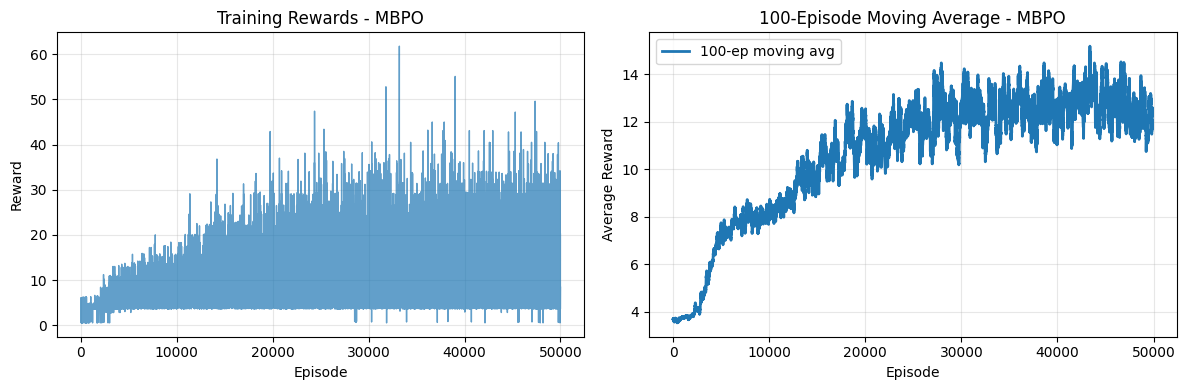


Training Summary:
  Total Episodes: 50000
  Avg Reward (last 100): 12.27
  Max Reward: 61.80
  Training Time: 37751.6s


In [28]:
# Save trained model
model_dir = Path('saved_models/mbpo')
model_dir.mkdir(parents=True, exist_ok=True)

# Save policies
policy_path = model_dir / 'policy_model.pt'
torch.save(agent.policy.state_dict(), policy_path)
print(f"✓ Policy saved to {policy_path}")

# Save world models
for i, model in enumerate(agent.world_models):
    world_path = model_dir / f'world_model_{i}.pt'
    torch.save(model.state_dict(), world_path)
print(f"✓ {len(agent.world_models)} world models saved")

# Save latent policy
latent_policy_path = model_dir / 'latent_policy_model.pt'
torch.save(agent.latent_policy.state_dict(), latent_policy_path)
print(f"✓ Latent policy saved to {latent_policy_path}")

# Save training metadata
import json
metadata = {
    'total_episodes': len(rewards),
    'average_reward_last_100': float(np.mean(rewards[-100:])) if len(rewards) >= 100 else float(np.mean(rewards)) if rewards else 0.0,
    'max_reward': float(np.max(rewards)) if rewards else 0.0,
    'training_time': training_time,
    'hyperparameters': {
        'gamma': agent.gamma,
        'eps_clip': agent.eps_clip,
        'batch_size': agent.batch_size,
    }
}

metadata_path = model_dir / 'metadata.json'
with open(metadata_path, 'w') as f:
    json.dump(metadata, f, indent=2)
print(f"✓ Metadata saved to {metadata_path}")

# Plot training rewards
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(rewards, linewidth=1, alpha=0.7)
plt.xlabel('Episode')
plt.ylabel('Reward')
plt.title('Training Rewards - MBPO')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
if len(rewards) >= 100:
    moving_avg = np.convolve(rewards, np.ones(100) / 100, mode='valid')
    plt.plot(moving_avg, linewidth=2, label='100-ep moving avg')
    plt.xlabel('Episode')
    plt.ylabel('Average Reward')
    plt.title('100-Episode Moving Average - MBPO')
    plt.grid(True, alpha=0.3)
    plt.legend()

plt.tight_layout()
plt.savefig(model_dir / 'training_rewards.png', dpi=100)
plt.show()

print(f"\nTraining Summary:")
print(f"  Total Episodes: {len(rewards)}")
if rewards:
    print(f"  Avg Reward (last 100): {np.mean(rewards[-100:]):.2f}")
    print(f"  Max Reward: {np.max(rewards):.2f}")
print(f"  Training Time: {training_time:.1f}s")
